TiffPage 0: TypeError: read_bytes() missing 3 required positional arguments: 'dtype', 'count', and 'offsetsize'


0.0451 0.00203401


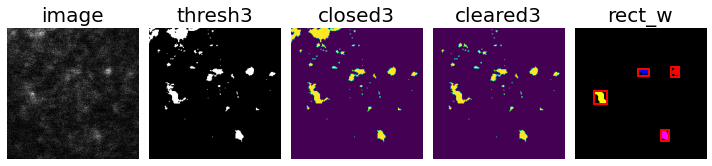

TiffPage 0: TypeError: read_bytes() missing 3 required positional arguments: 'dtype', 'count', and 'offsetsize'


0.0451 0.00203401


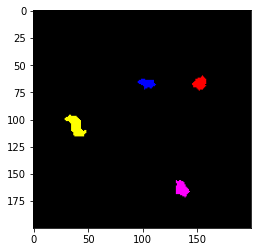

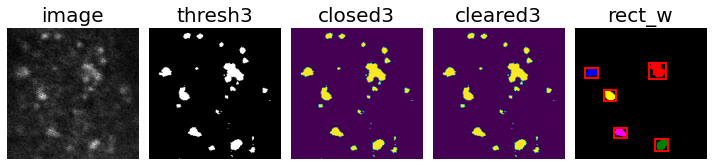

TiffPage 0: TypeError: read_bytes() missing 3 required positional arguments: 'dtype', 'count', and 'offsetsize'


0.0451 0.00203401


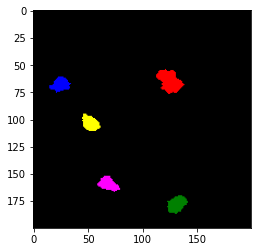

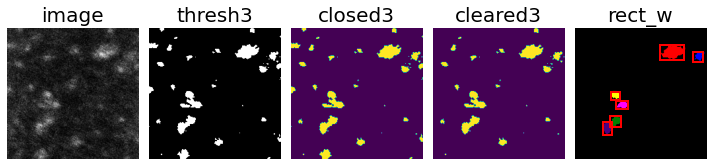

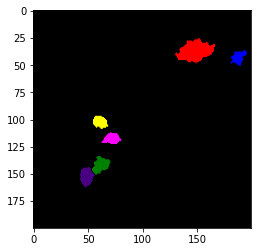

In [16]:
# Version for eSRRF images and confocal images
# Only segmentation and data extraction (no classifier)
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from glob import glob
import imageio as iio
import pandas as pd
import numpy as np
import seaborn as sns 
import statistics
from statistics import mean
import skimage
from skimage import data, filters, measure, morphology
from skimage.filters import threshold_otsu
from skimage.segmentation import clear_border, watershed
from skimage.morphology import closing, square, disk
from skimage.color import label2rgb
from skimage.measure import label, regionprops, regionprops_table
from skimage.feature import peak_local_max
import os
from os import listdir
from os.path import isfile, join
import scipy.ndimage.morphology as ndi
from scipy import ndimage as ndi
from scipy.ndimage import gaussian_filter
import openpyxl
from openpyxl.utils.dataframe import dataframe_to_rows
from PIL import Image, ImageFilter
import xlsxwriter
from sklearn import preprocessing
from math import sqrt
from sklearn import metrics
from matplotlib.colors import ListedColormap
from pylab import rcParams
from scipy import stats
from skimage import morphology
import cv2
from scipy.stats import gaussian_kde




def paths(mypath, pixel, sensitivity, area_th, picture_flag):
    p=[]
    names=[]
    onlyfiles = [f for f in listdir(mypath) if isfile(join(mypath, f))]
    for i in onlyfiles:
        if i.endswith(".tif"):
            names.append(i)
            path=os.path.join(mypath, i)
            p.append(path)

    count=0 
    seg=0
    for i in range(len(p)):
        count+=1
        seg+=1
        name=names[i]
        #print(name)
        b=glob(p[i])
        image=iio.imread(b[0])
        mean=image[i].mean()
        props4, arry_im, list_size4, mean_area, var_size, density, list_fluo, list_relative_fluo, mean_fluo, var_fluo, list_intensity_max, mean_intensity_max, list_intensity_min, mean_intensity_min, list_area_filled, mean_area_filled, list_axis_major_length, mean_axis_major_length, list_axis_minor_length, mean_axis_minor_length, list_eccentricity, mean_eccentricity, list_equivalent_diameter_area, mean_equivalent_diameter_area,  list_perimeter, mean_perimeter, list_label, sum_label, image, thresh3, closed3, cleared3, image_label_overlay4, label_image4, SCI,fwhm_area, density_microns, me =mybin(image, pixel, sensitivity, area_th)
        if picture_flag!=0:
            pic(image, thresh3, closed3, cleared3,image_label_overlay4, label_image4, name, mypath, seg, area_th, picture_flag)
        
        columns = ["name","area","mean_area", "var_area", "density", "intensity", "relative_intensity", "mean_intensity", "var_intensity", "max_intensity", "mean_max_intensity", "min_intensity", "mean_min_intensity", "area_filled", "mean_area_filled", "major_axis_length", "mean_major_axis_length", "minor_axis_length", "mean_minor_axis_length", "eccentricity", "mean_eccentricity", "equivalent_diameter_area", "mean_equivalent_diameter_area", "perimeter", "mean_perimeter", "label", "sum_label", "SCI", "fwhm_area", "density_microns", "mean_image_intensity"]
        new=list_size4
        if len(list_size4)>0:
            for j in range (len(list_size4)):

                new[j]= [name, list_size4[j], mean_area, var_size, density, list_fluo[j], list_relative_fluo[j], mean_fluo, var_fluo, list_intensity_max[j], mean_intensity_max, list_intensity_min[j], mean_intensity_min, list_area_filled[j], mean_area_filled, list_axis_major_length[j], mean_axis_major_length, list_axis_minor_length[j], mean_axis_minor_length, list_eccentricity[j], mean_eccentricity, list_equivalent_diameter_area[j], mean_equivalent_diameter_area,  list_perimeter[j], mean_perimeter, list_label[j], sum_label, SCI, fwhm_area, density_microns, me ]

            rows = new
            data = pd.DataFrame(rows, columns=columns)

        else: 
            new=[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, SCI, fwhm_area, 0, me]]
            new[0][0]=name

            rows=new
            data=pd.DataFrame(rows, columns=columns)
            
        if count==1:

            out_path = mypath+"\_results.xlsx"
            writer = pd.ExcelWriter(out_path , engine='xlsxwriter')
            data.to_excel(writer, sheet_name='Sheet1', header=True, index=False)
            writer.save()
            writer.close()
        else: 

            workbook = openpyxl.load_workbook(out_path)  # load workbook if already exists
            sheet = workbook['Sheet1']  # declare the active sheet 
            for row in dataframe_to_rows(data, header = False, index = False):
                sheet.append(row)
            workbook.save(out_path)  # save workbook
            workbook.close()  # close workbook
        
        

def pic(image, thresh3, closed3, cleared3,image_label_overlay4, label_image4, name, mypath, seg, area_th, picture_flag):
    
    fig, axes = plt.subplots(nrows=1, ncols=5, figsize=(10, 10),sharex=True, sharey=True)
    ax = axes.ravel()

    ax[0].imshow(image, cmap=plt.cm.gray)
    ax[0].axis('off')
    ax[0].set_title('image', fontsize=20)

    ax[1].imshow(thresh3, cmap=plt.cm.gray)
    ax[1].axis('off')
    ax[1].set_title('thresh3', fontsize=20)
    
    ax[2].imshow(closed3)
    ax[2].axis('off')
    ax[2].set_title('closed3', fontsize=20)

    ax[3].imshow(cleared3)
    ax[3].axis('off')
    ax[3].set_title('cleared3', fontsize=20)
    
    ax[4].imshow(image_label_overlay4)
    for region in regionprops(label_image4):
    # take regions with large enough areas
        if region.area >= area_th: # changed from 1
            # draw rectangle around segmented ND
            minr, minc, maxr, maxc = region.bbox
            rect = mpatches.Rectangle((minc, minr), maxc - minc, maxr - minr, fill=False, edgecolor='red', linewidth=2)
            ax[4].add_patch(rect)
    
    ax[4].axis('off')
    ax[4].set_title('rect_w', fontsize=20)
    

    fig.tight_layout()
    pic_path=os.path.join(mypath, name)
    pic_path2=pic_path +str(seg)+".png"
    plt.savefig(pic_path2)
    plt.show()
    plt.close()
    if picture_flag==2:
        
        plt.imshow(image_label_overlay4, cmap=plt.cm.gray)
        out_path_pic = mypath+"\\"+name+"segmented2.png" 
        plt.savefig(out_path_pic, dpi=800) #can change dpi to 1500 eg. for higher resolution images

     
        
        ## try same size:
        #height, width = image.shape[:2]
        #dpi = 800  # Dots per inch; you can adjust this

        # Compute figure size in inches
        #figsize = width / dpi, height / dpi

        # Plot without axes and padding
        #fig = plt.figure(figsize=figsize, dpi=dpi)
        #ax = fig.add_axes([0, 0, 1, 1])  
        #out_path_pic = mypath+"\\"+name+"segmented2.png" 
        #fig.savefig('out_path_pic', dpi=dpi, bbox_inches='tight', pad_inches=0)
        
        #plt.close(fig)
        
    
        
def sci(bild):
   
    smooth_kernel = np.array([
        [1, 1, 1],
        [1, 8, 1],
        [1, 1, 1]
    ], dtype=np.float32) / 16.0
    
    smoothed_image = cv2.filter2D(bild, -1, smooth_kernel, borderType=cv2.BORDER_REFLECT)
    intensity= np.asarray(smoothed_image)
    
    lys = intensity.tolist()
    flat = [val for sublist in lys for val in sublist]
    flat.sort()
    l=len(flat)
    low5= int(l*5/100)
    high5= l-low5
    lowarry=flat[:low5]
    higharry=flat[high5:]
    
    mean1=np.mean(lowarry)
    median1=np.median(lowarry)
   
    mean2=np.mean(higharry)
    median2=np.median(higharry)
    ratio=mean2/mean1
    ratio2=median1/median2
    
    if mean1==0:
        ratio=0
        
    # for FWHM:
    percent=5
    me=bild.mean()

    threshold = np.percentile(bild, 100 - percent)
    coords = np.argwhere(bild >= threshold)
    lys_coords=[tuple(coord) for coord in coords]
 
    df = pd.DataFrame(coords, columns =['pos_x', 'pos_y'])
    
    arry_KDE = df.to_numpy().T  # Now shape (2, n_samples)

    intensity_weights = bild[coords[:,0], coords[:,1]]

    kde = gaussian_kde(arry_KDE)
    kde = gaussian_kde(arry_KDE, weights=intensity_weights)

    # Create a grid for plotting
    xmin, xmax = 0, bild.shape[1]
    ymin, ymax = 0, bild.shape[0]
    xx, yy = np.mgrid[xmin:xmax:100j, ymin:ymax:100j]  # grid of shape (100, 100)
    grid_coords = np.vstack([yy.ravel(), xx.ravel()])  # shape (2, N)

    # Evaluate KDE on grid
    zz = kde(grid_coords).reshape(xx.shape)

    half_max = 0.5 * np.max(zz)
    fwhm_area = np.sum(zz >= half_max)

    #print(f"FWHM area (pixels above half max): {fwhm_area}")

    return ratio, fwhm_area
    
    
    

        
def mybin(image, pixel, sensitivity, area_th):
  
    pixelsize=(pixel/image.shape[0])**2 # enter the pixelsize in microns
    pixellength=pixel/image.shape[0] # enter the pixelsize in microns
    print(pixellength,pixelsize )

    SCI, fwhm_area=sci(image)
    
    me=image.mean()
    ratio = sensitivity * me # here you can change the ratio value
    blurred = gaussian_filter(image, sigma=0.9)
    
    thresh3=1*blurred
    thresh3[ thresh3<ratio]=0
    thresh3[thresh3>ratio]=1
    
    closed3 = closing(thresh3) #dilation followed by an erosion
    cleared3 = clear_border(closed3)
    distance3 = ndi.distance_transform_edt(cleared3)
    coords3 = peak_local_max(distance3, labels=cleared3, footprint=np.ones((5, 5)), min_distance=8, exclude_border=True)#changed from 8 to 15 for STREMimages!
    mask3 = np.zeros(distance3.shape, dtype=bool)
    mask3[tuple(coords3.T)] = True
    markers3, _ = ndi.label(mask3)
    labels_water3 = watershed(-distance3, markers3, mask=cleared3, watershed_line=True)
    label_image4 = label(labels_water3)
    label_image4=morphology.remove_small_objects(label_image4, 100) ## added for surfremove if doesnt work!

    image_label_overlay4 = label2rgb(label_image4, image=image, bg_label=0, alpha=1)
    
    props4=regionprops(label_image=label_image4, intensity_image=image, cache=True)
    
    list_size4=[] #for watershed
    for i in range (len (props4)):
        if props4[i].area >=area_th:
            list_size4.append(props4[i].area *pixelsize)
    if len(list_size4)>0:
        mean_area=mean(list_size4)

    else:
        mean_area=0
        
    if len(list_size4)>0:
        density=(sum(list_size4)/image.shape[0])

    else:
        density=0
        
    
    list_fluo=[]
    list_relative_fluo=[]
    for i in range (len (props4)):
        if props4[i].area >=area_th:
            list_fluo.append(props4[i].mean_intensity)
            list_relative_fluo.append((props4[i].mean_intensity)/me)
    if len(list_size4)>0:
        mean_fluo=mean(list_fluo)
        mean_relative_fluo=mean(list_relative_fluo)
    else:
        mean_fluo=0
        mean_relative_fluo=0
        
    list_intensity_max=[]
    for i in range (len (props4)):
        if props4[i].area >=area_th:
             list_intensity_max.append(props4[i].max_intensity)
    if len(list_size4)>0:
        mean_intensity_max=mean(list_intensity_max)
    else:
        mean_intensity_max=0
                 
    list_intensity_min=[]
    for i in range (len (props4)):
        if props4[i].area >=area_th:
            list_intensity_min.append(props4[i].min_intensity)
    if len(list_size4)>0:
        mean_intensity_min=mean(list_intensity_min)
    else:
        mean_intensity_min=0

    list_area_filled=[]
    for i in range (len (props4)):
        if props4[i].area >=area_th:
            list_area_filled.append(props4[i].filled_area *pixelsize)
    if len(list_size4)>0:
        mean_area_filled=mean(list_area_filled)*pixelsize
    else:
        mean_area_filled=0
 
    
    list_axis_major_length=[]
    for i in range (len (props4)):
        if props4[i].area >=area_th:
            list_axis_major_length.append(props4[i].major_axis_length*pixellength)
    if len(list_size4)>0:
        mean_axis_major_length=mean(list_axis_major_length)*pixellength
    else:
        mean_axis_major_length=0

    list_axis_minor_length=[]
    for i in range (len (props4)):
        if props4[i].area >=area_th:
            list_axis_minor_length.append(props4[i].minor_axis_length*pixellength)
    if len(list_size4)>0:
        mean_axis_minor_length=mean(list_axis_minor_length)*pixellength
    else:
        mean_axis_minor_length=0
    
    list_eccentricity=[]
    for i in range (len (props4)):
        if props4[i].area >=area_th:
            list_eccentricity.append(props4[i].eccentricity)
            
    if len(list_size4)>0:
        mean_eccentricity=mean(list_eccentricity)
    else:
        mean_eccentricity=0
    
    list_equivalent_diameter_area=[]
    for i in range (len (props4)):
        if props4[i].area >=area_th:
             list_equivalent_diameter_area.append(props4[i].equivalent_diameter*pixellength)
    if len(list_size4)>0:
        mean_equivalent_diameter_area=mean(list_equivalent_diameter_area)*pixellength
    else:
        mean_equivalent_diameter_area=0
    
    list_perimeter=[]
    for i in range (len (props4)):
        if props4[i].area >=area_th:
            list_perimeter.append(props4[i].perimeter*pixellength)
            
    if len(list_size4)>0:
        mean_perimeter=mean(list_perimeter)*pixellength
    else:
        mean_perimeter=0
    
    list_label=[]
    for i in range (len (props4)):
        if props4[i].area >=area_th:
            list_label.append(props4[i].label)
    if len(list_size4)>0:
        sum_label=len(list_label)
       
        
    else:
        sum_label=0

    if len(list_size4)>0:
        var_fluo=2*(statistics.pstdev(list_fluo))
        var_size=2*(statistics.pstdev(list_size4))
        density_microns=sum_label/pixel
        #print(sum_label, pixel, density_microns)
    else:
        var_fluo=0
        var_size=0 
        density_microns=0
    
    
    arry_im=np.array([0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0, 0.0, 0.0, 0.0])
    arry_im[0]=me
    arry_im[1]=np.var(image)
    arry_im[2]=blurred.mean()
    arry_im[3]=np.var(blurred)
    arry_im[4]=mean_fluo
    arry_im[5]=var_fluo
    arry_im[6]=mean_area
    arry_im[7]=var_size
    arry_im[8]=mean_intensity_max
    arry_im[9]=mean_intensity_min
    arry_im[10]=mean_area_filled
    arry_im[11]=mean_axis_major_length
    arry_im[12]=mean_axis_minor_length
    arry_im[13]=mean_eccentricity
    arry_im[14]=mean_equivalent_diameter_area
    arry_im[15]=mean_perimeter  
    arry_im[16]=sum_label
    arry_im[17]=density
    arry_im[18]=mean_relative_fluo
    arry_im[19]=density_microns

 


    return(props4, arry_im, list_size4, mean_area, var_size, density, list_fluo, list_relative_fluo, mean_fluo, var_fluo, list_intensity_max, mean_intensity_max, list_intensity_min, mean_intensity_min, list_area_filled, mean_area_filled, list_axis_major_length, mean_axis_major_length, list_axis_minor_length, mean_axis_minor_length, list_eccentricity, mean_eccentricity, list_equivalent_diameter_area, mean_equivalent_diameter_area,  list_perimeter, mean_perimeter, list_label, sum_label, image, thresh3, closed3, cleared3, image_label_overlay4, label_image4, SCI,fwhm_area, density_microns, me )
    
    
###########
###########
# IMPORTANT NOTES:
# The images have to be 16 bit (not 32 bit)

###########
# Input parameters:

# pixel size: check the size of your image in pixels e.g using Fiji: 
# Example: If you have an image that is 200x200, 9.02x9.02 um -> enter 9.02

# Sensitivity: for different sensitivity change the ratio value (eg. from 2.0 to 2.7) from intitial threshholding
# Usually Sensitivity = 2.0 works for a broad range of images (eSRRF and confocal)

# my_path: is the input path to the folder of your images

# area_th: minimum area that you expect of your subcellular dots
# Example: area_th=1 for REM NDs. area_th=100 for eSRRF images

# picture_flag: Choose if you want pictures of the segmentation steps and or the final segmentation
# Example: 
# picture_flag=0 (no picture)
# picture_flag=1 (will save a picture of the segmentation steps)
# picture_flag=2 (will save a picture of the segmentation steps and a high resolution image of the final segmentaiton)



###########


pixel=9.02

area_th=1

sensitivity=2.0

picture_flag=2


my_path=r"C:\Users\miche\Desktop\REM_MS\test"



    
paths(my_path, pixel, sensitivity, area_th, picture_flag)